In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
file_path = "ev_vs_petrol_dataset_v3-selected-columns.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1200, 16)


,country,year,ev_sales,petrol_car_sales,diesel_car_sales,total_vehicle_sales,ev_market_share,charging_stations,avg_ev_range_km,fuel_price_usd_per_liter,electricity_price_usd_per_kwh,co2_emissions_transport_mt,ev_subsidy_usd,emission_regulation_score,ev_growth_rate_yoy,is_ev_dominant
0,Australia,2010,5,92877,61921,154803,0.00,0,124,1.09,0.149,88.7,0,30.4,0.00,0
1,Australia,2010,57,535933,73089,609079,0.01,0,124,1.09,0.149,88.7,0,30.4,0.00,0
2,Australia,2010,37,235282,20462,255781,0.01,0,124,1.09,0.149,88.7,0,30.4,0.00,0
3,Australia,2011,11,98092,65395,163498,0.01,105,133,1.09,0.163,88.3,0,30.8,120.00,0
4,Australia,2011,129,569679,77684,647492,0.02,105,133,1.09,0.163,88.3,0,30.8,126.32,0


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

Rows: 1200
Columns: 16

Column names:
['country', 'year', 'ev_sales', 'petrol_car_sales', 'diesel_car_sales', 'total_vehicle_sales', 'ev_market_share', 'charging_stations', 'avg_ev_range_km', 'fuel_price_usd_per_liter', 'electricity_price_usd_per_kwh', 'co2_emissions_transport_mt', 'ev_subsidy_usd', 'emission_regulation_score', 'ev_growth_rate_yoy', 'is_ev_dominant']

Data types:
country                              str
year                               int64
ev_sales                           int64
petrol_car_sales                   int64
diesel_car_sales                   int64
total_vehicle_sales                int64
ev_market_share                  float64
charging_stations                  int64
avg_ev_range_km                    int64
fuel_price_usd_per_liter         float64
electricity_price_usd_per_kwh    float64
co2_emissions_transport_mt       float64
ev_subsidy_usd                     int64
emission_regulation_score        float64
ev_growth_rate_yoy               float64
is

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

Rows: 1200
Columns: 16

Column names:
['country', 'year', 'ev_sales', 'petrol_car_sales', 'diesel_car_sales', 'total_vehicle_sales', 'ev_market_share', 'charging_stations', 'avg_ev_range_km', 'fuel_price_usd_per_liter', 'electricity_price_usd_per_kwh', 'co2_emissions_transport_mt', 'ev_subsidy_usd', 'emission_regulation_score', 'ev_growth_rate_yoy', 'is_ev_dominant']

Data types:
country                              str
year                               int64
ev_sales                           int64
petrol_car_sales                   int64
diesel_car_sales                   int64
total_vehicle_sales                int64
ev_market_share                  float64
charging_stations                  int64
avg_ev_range_km                    int64
fuel_price_usd_per_liter         float64
electricity_price_usd_per_kwh    float64
co2_emissions_transport_mt       float64
ev_subsidy_usd                     int64
emission_regulation_score        float64
ev_growth_rate_yoy               float64
is

In [ ]:
duplicate_groups = (
    df.groupby(["country", "year"])
      .size()
      .reset_index(name="count")
)

print(duplicate_groups["count"].value_counts().sort_index())

count
3    400
Name: count, dtype: int64


In [ ]:
duplicates = df[df.duplicated(
    subset=["country", "year"],
    keep=False
)].sort_values(["country", "year"])

duplicates.head(20)

,country,year,ev_sales,petrol_car_sales,diesel_car_sales,total_vehicle_sales,ev_market_share,charging_stations,avg_ev_range_km,fuel_price_usd_per_liter,electricity_price_usd_per_kwh,co2_emissions_transport_mt,ev_subsidy_usd,emission_regulation_score,ev_growth_rate_yoy,is_ev_dominant
0,Australia,2010,5,92877,61921,154803,0.00,0,124,1.090,0.149,88.7,0,30.4,0.00,0
1,Australia,2010,57,535933,73089,609079,0.01,0,124,1.090,0.149,88.7,0,30.4,0.00,0
2,Australia,2010,37,235282,20462,255781,0.01,0,124,1.090,0.149,88.7,0,30.4,0.00,0
3,Australia,2011,11,98092,65395,163498,0.01,105,133,1.090,0.163,88.3,0,30.8,120.00,0
4,Australia,2011,129,569679,77684,647492,0.02,105,133,1.090,0.163,88.3,0,30.8,126.32,0
5,Australia,2011,80,252643,21969,274692,0.03,105,133,1.090,0.163,88.3,0,30.8,116.22,0
6,Australia,2012,17,96466,64310,160793,0.01,191,135,1.067,0.177,89.5,0,31.6,84.39,0
7,Australia,2012,195,571555,77939,649689,0.03,191,135,1.067,0.177,89.5,0,31.6,51.16,0
8,Australia,2012,117,246448,21430,267995,0.04,191,135,1.067,0.177,89.5,0,31.6,77.82,0
9,Australia,2013,36,101461,67640,169137,0.02,306,143,1.033,0.192,90.0,0,33.2,93.10,0


In [ ]:
sum_columns = [
    "ev_sales",
    "petrol_car_sales",
    "diesel_car_sales"
]
first_columns = [
    "charging_stations",
    "avg_ev_range_km",
    "fuel_price_usd_per_liter",
    "electricity_price_usd_per_kwh",
    "co2_emissions_transport_mt",
    "ev_subsidy_usd",
    "emission_regulation_score"
]

In [ ]:
cleaned_df = (
    df.groupby(["country", "year"], as_index=False)
      .agg({
          "ev_sales": "sum",
          "petrol_car_sales": "sum",
          "diesel_car_sales": "sum",
          
          "charging_stations": "first",
          "avg_ev_range_km": "first",
          "fuel_price_usd_per_liter": "first",
          "electricity_price_usd_per_kwh": "first",
          "co2_emissions_transport_mt": "first",
          "ev_subsidy_usd": "first",
          "emission_regulation_score": "first"
      })
)
print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)

Original shape: (1200, 16)
Cleaned shape: (400, 12)


In [ ]:
cleaned_df["total_vehicle_sales"] = (
    cleaned_df["ev_sales"]
    + cleaned_df["petrol_car_sales"]
    + cleaned_df["diesel_car_sales"]
)

In [ ]:
cleaned_df["ev_market_share"] = (
    cleaned_df["ev_sales"]
    / cleaned_df["total_vehicle_sales"]
    * 100
)
cleaned_df["ev_market_share"] = (
    cleaned_df["ev_market_share"].round(2)
)

In [ ]:
cleaned_df = cleaned_df.sort_values(
    ["country", "year"]
).reset_index(drop=True)
cleaned_df["ev_growth_rate_yoy"] = (
    cleaned_df.groupby("country")["ev_sales"]
    .pct_change()
    * 100
)
cleaned_df["ev_growth_rate_yoy"] = (
    cleaned_df["ev_growth_rate_yoy"]
    .replace([np.inf, -np.inf], np.nan)
)
cleaned_df["is_ev_dominant"] = (
    cleaned_df["ev_market_share"] >= 50
).astype(int)

Duplicate country-year combinations: 0
Exact duplicate rows: 0

Missing values:
country                           0
year                              0
ev_sales                          0
petrol_car_sales                  0
diesel_car_sales                  0
total_vehicle_sales               0
ev_market_share                   0
charging_stations                 0
avg_ev_range_km                   0
fuel_price_usd_per_liter          0
electricity_price_usd_per_kwh     0
co2_emissions_transport_mt        0
ev_subsidy_usd                    0
emission_regulation_score         0
ev_growth_rate_yoy               25
is_ev_dominant                    0
dtype: int64
Total sales errors: 0
Market share errors: 0
Dominance errors: 0


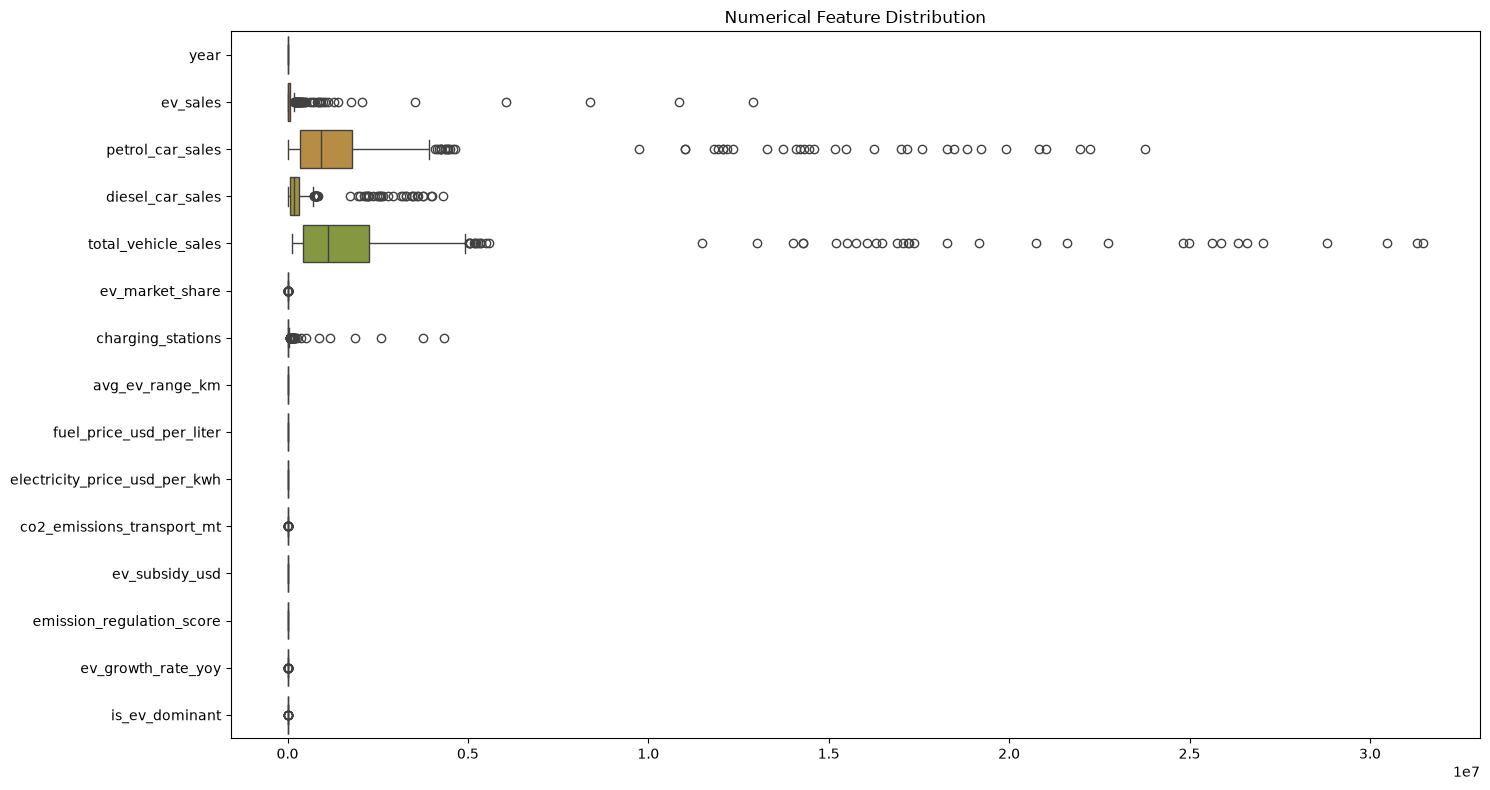

Negative EV sales: 0
Negative petrol sales: 0
Negative diesel sales: 0
Negative charging stations: 0
EV market share outside 0-100: 0
Final dataset shape: (400, 16)

Final columns:
['country', 'year', 'ev_sales', 'petrol_car_sales', 'diesel_car_sales', 'total_vehicle_sales', 'ev_market_share', 'charging_stations', 'avg_ev_range_km', 'fuel_price_usd_per_liter', 'electricity_price_usd_per_kwh', 'co2_emissions_transport_mt', 'ev_subsidy_usd', 'emission_regulation_score', 'ev_growth_rate_yoy', 'is_ev_dominant']

Missing values:
country                           0
year                              0
ev_sales                          0
petrol_car_sales                  0
diesel_car_sales                  0
total_vehicle_sales               0
ev_market_share                   0
charging_stations                 0
avg_ev_range_km                   0
fuel_price_usd_per_liter          0
electricity_price_usd_per_kwh     0
co2_emissions_transport_mt        0
ev_subsidy_usd                    0
em

In [ ]:
column_order = [
    "country",
    "year",
    "ev_sales",
    "petrol_car_sales",
    "diesel_car_sales",
    "total_vehicle_sales",
    "ev_market_share",
    "charging_stations",
    "avg_ev_range_km",
    "fuel_price_usd_per_liter",
    "electricity_price_usd_per_kwh",
    "co2_emissions_transport_mt",
    "ev_subsidy_usd",
    "emission_regulation_score",
    "ev_growth_rate_yoy",
    "is_ev_dominant"
]

cleaned_df = cleaned_df[column_order]
 
print(
    "Duplicate country-year combinations:",
    cleaned_df.duplicated(
        subset=["country", "year"]
    ).sum()
)
print("Exact duplicate rows:", cleaned_df.duplicated().sum())
print("\nMissing values:")
print(cleaned_df.isnull().sum())
total_check = (
    cleaned_df["total_vehicle_sales"]
    ==
    (
        cleaned_df["ev_sales"]
        + cleaned_df["petrol_car_sales"]
        + cleaned_df["diesel_car_sales"]
    )
)

print("Total sales errors:", (~total_check).sum())
share_check = np.isclose(
    cleaned_df["ev_market_share"],
    (
        cleaned_df["ev_sales"]
        / cleaned_df["total_vehicle_sales"]
        * 100
    ),
    atol=0.01
)

print("Market share errors:", (~share_check).sum())
dominance_check = (
    cleaned_df["is_ev_dominant"]
    ==
    (cleaned_df["ev_market_share"] >= 50).astype(int)
)

print("Dominance errors:", (~dominance_check).sum())
numeric_columns = cleaned_df.select_dtypes(
    include=np.number
).columns

cleaned_df[numeric_columns].describe().T
plt.figure(figsize=(15, 8))

sns.boxplot(
    data=cleaned_df[numeric_columns],
    orient="h"
)

print("Negative EV sales:",
      (cleaned_df["ev_sales"] < 0).sum())

print("Negative petrol sales:",
      (cleaned_df["petrol_car_sales"] < 0).sum())

print("Negative diesel sales:",
      (cleaned_df["diesel_car_sales"] < 0).sum())

print("Negative charging stations:",
      (cleaned_df["charging_stations"] < 0).sum())

print("EV market share outside 0-100:",
      ((cleaned_df["ev_market_share"] < 0) |
       (cleaned_df["ev_market_share"] > 100)).sum())
print("Final dataset shape:", cleaned_df.shape)

print("\nFinal columns:")
print(cleaned_df.columns.tolist())

print("\nMissing values:")
print(cleaned_df.isnull().sum())

print("\nDuplicate country-year combinations:",
      cleaned_df.duplicated(["country", "year"]).sum())

cleaned_df.head(10)
output_file = "ev_vs_petrol_dataset_cleaned.csv"

cleaned_df.to_csv(
    output_file,
    index=False
)

print(f"Cleaned dataset saved as: {output_file}")